In [36]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory


# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [37]:
# ==============================================================================
# BLOCK 1: CLEAN RESET, SETUP & DOWNLOAD ALL DATASETS
# ==============================================================================
# 1. Clean previous run & clone fresh repository
%cd /kaggle/working
!rm -rf Birth-Death-acceleration-of-diffusion-sampling
!git clone https://github.com/Aryaman-Prasad/Birth-Death-acceleration-of-diffusion-sampling.git
%cd Birth-Death-acceleration-of-diffusion-sampling

# 2. Install dependencies with pretrained diffusers & FID support
!pip install -e ".[pretrained,fid]" matplotlib kagglehub huggingface_hub -q

import os
import tarfile
import kagglehub
import pandas as pd
from IPython.display import Image, display, FileLink
from huggingface_hub import hf_hub_download

# 3. Download and extract CIFAR-10 into data/
print("\n[+] Downloading & extracting CIFAR-10...")
os.makedirs("data", exist_ok=True)
cifar_tar = hf_hub_download(
    repo_id="xingslong/cifar-10-batches-py",
    filename="cifar-10-python.tar.gz",
    repo_type="dataset",
)
with tarfile.open(cifar_tar, "r:gz") as tar:
    tar.extractall("data")
print("[+] CIFAR-10 ready in data/cifar-10-batches-py")

# 4. Download CelebA-HQ 256x256 from Kaggle and export path
print("\n[+] Fetching CelebA-HQ 256x256 dataset...")
celeba_hq_path = kagglehub.dataset_download("badasstechie/celebahq-resized-256x256")
os.environ["CELEBA_HQ_PATH"] = celeba_hq_path
print(f"[+] CelebA-HQ 256 ready at: {celeba_hq_path}")

/kaggle/working
Cloning into 'Birth-Death-acceleration-of-diffusion-sampling'...
remote: Enumerating objects: 289, done.
remote: Counting objects: 100% (289/289), done.
remote: Compressing objects: 100% (210/210), done.
remote: Total 289 (delta 117), reused 180 (delta 61), pack-reused 0 (from 0)
Receiving objects: 100% (289/289), 174.73 KiB | 4.16 MiB/s, done.
Resolving deltas: 100% (117/117), done.
/kaggle/working/Birth-Death-acceleration-of-diffusion-sampling
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for diffusion-sampling-framework (pyproject.toml) ... done

[+] Downloading & extracting CIFAR-10...


/tmp/ipykernel_49/1788163748.py:29: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall("data")


[+] CIFAR-10 ready in data/cifar-10-batches-py

[+] Fetching CelebA-HQ 256x256 dataset...
[+] CelebA-HQ 256 ready at: /kaggle/input/datasets/badasstechie/celebahq-resized-256x256


[+] Running Toy 2D Gaussian Mixture benchmark on cuda...

Configuration          | Steps | BD    | MMD²     | Cov   | Unique   | Time(s)
--------------------------------------------------------------------------------
DDIM 5 (Baseline)      | 5     | NO    | 0.04575  | 8/8   | 1.00     | 0.161  
DDIM 5 + BD            | 5     | YES   | 0.03815  | 8/8   | 0.86     | 0.013  
DDIM 10 (Baseline)     | 10    | NO    | 0.00483  | 8/8   | 1.00     | 0.009  
DDIM 10 + Light BD     | 10    | YES   | 0.00410  | 8/8   | 1.00     | 0.015  
DDIM 10 + Heavy BD     | 10    | YES   | 0.00356  | 8/8   | 0.84     | 0.022  
DDIM 25 (Baseline)     | 25    | NO    | 0.00338  | 8/8   | 1.00     | 0.024  
DDIM 25 + BD           | 25    | YES   | 0.00197  | 8/8   | 1.00     | 0.041  
DDIM 50 (Baseline)     | 50    | NO    | 0.00170  | 8/8   | 1.00     | 0.047  
DDIM 50 + BD           | 50    | YES   | 0.00161  | 8/8   | 1.00     | 0.081  
[+] Saved 2D scatter comparison to: /kaggle/working/Birth-Death-acceler

,name,steps,birth_death,mmd2,mode_coverage,unique_fraction,elapsed_seconds
0,DDIM 5 (Baseline),5,False,0.04575,1.0,1.0000,0.1610
1,DDIM 5 + BD,5,True,0.03815,1.0,0.8613,0.0130
2,DDIM 10 (Baseline),10,False,0.00483,1.0,1.0000,0.0094
3,DDIM 10 + Light BD,10,True,0.00410,1.0,1.0000,0.0155
4,DDIM 10 + Heavy BD,10,True,0.00356,1.0,0.8398,0.0224
5,DDIM 25 (Baseline),25,False,0.00338,1.0,1.0000,0.0238
6,DDIM 25 + BD,25,True,0.00197,1.0,0.9980,0.0409
7,DDIM 50 (Baseline),50,False,0.00170,1.0,1.0000,0.0472
8,DDIM 50 + BD,50,True,0.00161,1.0,1.0000,0.0806



[+] 2D PARTICLE SCATTER PLOTS (OVERLAID ON TRUE GAUSSIAN MODES):


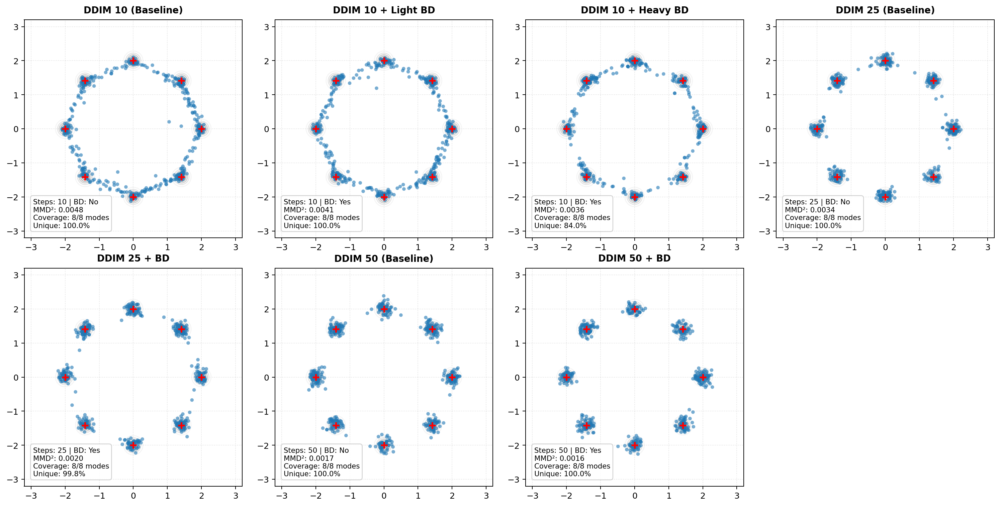


[+] QUALITY (MMD²) VS. DIVERSITY (UNIQUE %) BAR CHART:


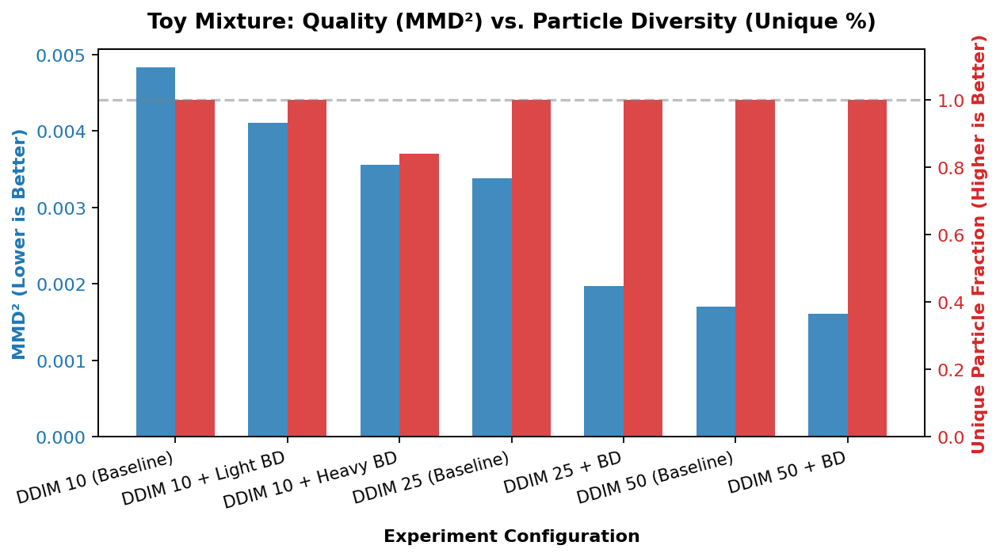


[+] Click below to download Toy Results Zip:


/kaggle/working/toy_results.zip

In [38]:
# ==============================================================================
# BLOCK 2: TOY 2D GAUSSIAN MIXTURE EXPERIMENTS
# ==============================================================================
# 1. Run toy benchmark (5 steps acts as warmup; 10 & 50 steps plotted)
!python3 scripts/run_and_plot_toy.py --count 512 --device cuda --output-dir toy_results

# 2. Display summary table
print("\n" + "="*85 + "\n[+] TOY MIXTURE RESULTS TABLE:\n" + "="*85)
df_toy = pd.read_csv("toy_results/toy_results.csv")
display(df_toy[["name", "steps", "birth_death", "mmd2", "mode_coverage", "unique_fraction", "elapsed_seconds"]])

# 3. Display 2D particle scatter plots & metrics bar chart
print("\n[+] 2D PARTICLE SCATTER PLOTS (OVERLAID ON TRUE GAUSSIAN MODES):")
display(Image("toy_results/toy_scatter_comparison.png"))

print("\n[+] QUALITY (MMD²) VS. DIVERSITY (UNIQUE %) BAR CHART:")
display(Image("toy_results/toy_metrics_barchart.png"))

# 4. Zip results and provide download link
!zip -q -r /kaggle/working/toy_results.zip toy_results
print("\n[+] Click below to download Toy Results Zip:")
FileLink('/kaggle/working/toy_results.zip')

[+] Initializing Deliverable 4 benchmark on cuda...
[+] Building empirical target density over 256 reference images...
[+] Loading 256 real reference images for FID...

[+] Executing 13 evaluation cases for Deliverable 4...
Case Name                | Steps | BD    | Time(s)  | Sec/Samp  | Unique   | FID    
-------------------------------------------------------------------------------------
ddim_5_baseline          | 5     | NO    | 0.29     | 0.0179    | 1.00     | 204.27 
ddim_5_bd                | 5     | YES   | 0.02     | 0.0014    | 1.00     | 198.05 
ddim_10_baseline         | 10    | NO    | 0.02     | 0.0014    | 1.00     | 144.74 
ddim_10_bd               | 10    | YES   | 0.03     | 0.0019    | 1.00     | 150.21 
ddim_25_baseline         | 25    | NO    | 0.06     | 0.0036    | 1.00     | 135.73 
ddim_25_bd               | 25    | YES   | 0.08     | 0.0048    | 1.00     | 136.55 
ddim_50_baseline         | 50    | NO    | 0.11     | 0.0070    | 1.00     | 129.88 
ddim_50_bd

,case_name,steps,birth_death,elapsed_seconds,seconds_per_sample,unique_fraction,fid
0,ddim_5_baseline,5,False,0.2862,0.0179,1.0000,204.270
1,ddim_5_bd,5,True,0.0225,0.0014,1.0000,198.047
2,ddim_10_baseline,10,False,0.0227,0.0014,1.0000,144.743
3,ddim_10_bd,10,True,0.0298,0.0019,1.0000,150.214
4,ddim_25_baseline,25,False,0.0574,0.0036,1.0000,135.732
5,ddim_25_bd,25,True,0.0765,0.0048,1.0000,136.554
6,ddim_50_baseline,50,False,0.1114,0.0070,1.0000,129.877
7,ddim_50_bd,50,True,0.1561,0.0098,1.0000,140.340
8,ablation_time_0.10,25,True,0.0738,0.0046,0.8125,165.427
9,ablation_time_1.00,25,True,0.0763,0.0048,0.5625,224.826



[+] GENERATED CIFAR-10 IMAGE SAMPLES:
--> Sample Grid: ablation_eta_0.0


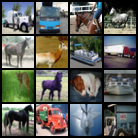

--> Sample Grid: ablation_k_1


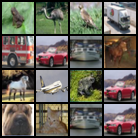

--> Sample Grid: ablation_k_5


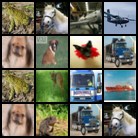

--> Sample Grid: ablation_time_0.10


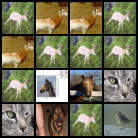

--> Sample Grid: ablation_time_1.00


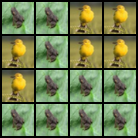

--> Sample Grid: ddim_10_baseline


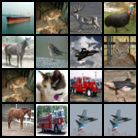

--> Sample Grid: ddim_10_bd


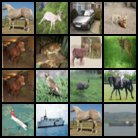

--> Sample Grid: ddim_25_baseline


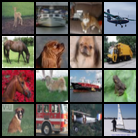

--> Sample Grid: ddim_25_bd


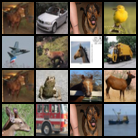

--> Sample Grid: ddim_50_baseline


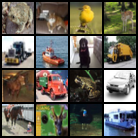

--> Sample Grid: ddim_50_bd


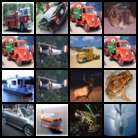

--> Sample Grid: ddim_5_baseline


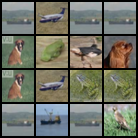

--> Sample Grid: ddim_5_bd


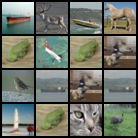


[+] PERFORMANCE & DIVERSITY CHARTS:
[+] Speed vs Quality (Steps vs FID):


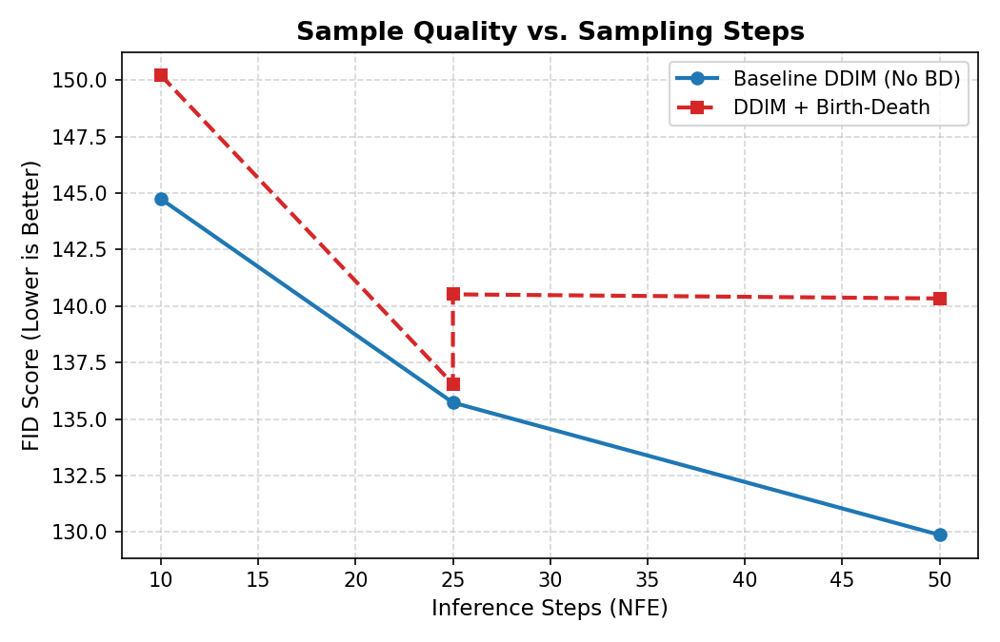

[+] Diversity Collapse (Unique Fraction vs BD Time):


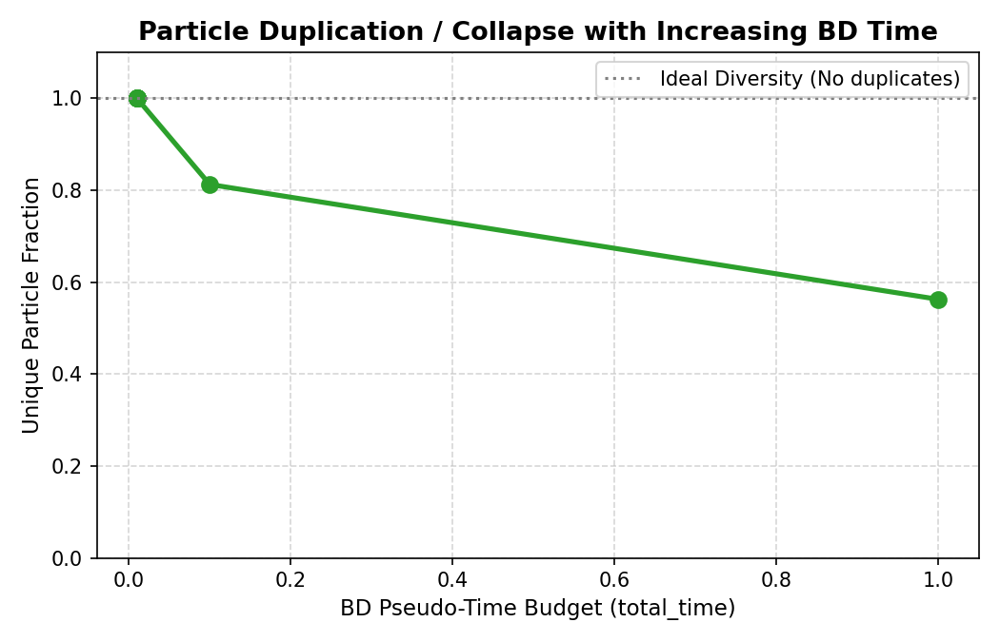

[+] Latency Overhead Comparison:


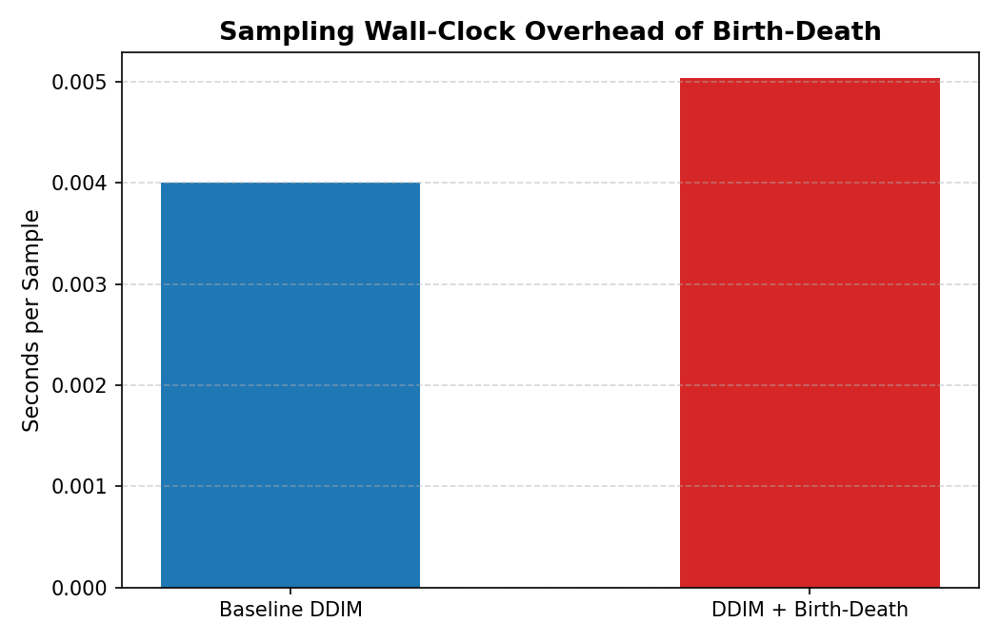


[+] Download CIFAR-10 Results Zip:


/kaggle/working/deliverable4_cifar10_results.zip

In [39]:
# ==============================================================================
# BLOCK 3: CIFAR-10 EVALUATION SUITE
# ==============================================================================
# 1. Run Deliverable 4 benchmark suite on CIFAR-10
!python3 scripts/run_deliverable4_eval.py \
  --dataset cifar10 \
  --data-dir data \
  --image-size 32 \
  --reference-count 256 \
  --fid-samples 256 \
  --fid-batch-size 32 \
  --device cuda \
  --output-dir deliverable4_cifar10

# 2. Display summary table
print("\n" + "="*85 + "\n[+] CIFAR-10 DELIVERABLE 4 RESULTS TABLE:\n" + "="*85)
df_cifar = pd.read_csv("deliverable4_cifar10/deliverable4_results.csv")
display(df_cifar[["case_name", "steps", "birth_death", "elapsed_seconds", "seconds_per_sample", "unique_fraction", "fid"]])

# 3. Display generated image sample grids
print("\n" + "="*85 + "\n[+] GENERATED CIFAR-10 IMAGE SAMPLES:\n" + "="*85)
import glob
from IPython.display import HTML

sample_imgs = sorted(glob.glob("deliverable4_cifar10/samples/*.png"))
for img_path in sample_imgs:
    case_title = os.path.basename(img_path).replace(".png", "")
    print(f"--> Sample Grid: {case_title}")
    display(Image(img_path, width=320))

# 4. Display generated charts
print("\n" + "="*85 + "\n[+] PERFORMANCE & DIVERSITY CHARTS:\n" + "="*85)
print("[+] Speed vs Quality (Steps vs FID):")
display(Image("deliverable4_cifar10/plots/fig1_steps_vs_fid.png"))

print("[+] Diversity Collapse (Unique Fraction vs BD Time):")
display(Image("deliverable4_cifar10/plots/fig2_diversity_collapse.png"))

print("[+] Latency Overhead Comparison:")
display(Image("deliverable4_cifar10/plots/fig3_latency_overhead.png"))

# 5. Zip and create download link
!zip -q -r /kaggle/working/deliverable4_cifar10_results.zip deliverable4_cifar10
print("\n[+] Download CIFAR-10 Results Zip:")
FileLink('/kaggle/working/deliverable4_cifar10_results.zip')

[+] Initializing Deliverable 4 benchmark on cuda...
[+] Building empirical target density over 256 reference images...
[+] Loading 256 real reference images for FID...

[+] Executing 13 evaluation cases for Deliverable 4...
Case Name                | Steps | BD    | Time(s)  | Sec/Samp  | Unique   | FID    
-------------------------------------------------------------------------------------
ddim_5_baseline          | 5     | NO    | 0.45     | 0.0283    | 1.00     | 95.76  
ddim_5_bd                | 5     | YES   | 0.19     | 0.0117    | 0.69     | 105.01 
ddim_10_baseline         | 10    | NO    | 0.29     | 0.0183    | 1.00     | 65.64  
ddim_10_bd               | 10    | YES   | 0.38     | 0.0236    | 1.00     | 81.63  
ddim_25_baseline         | 25    | NO    | 0.84     | 0.0524    | 1.00     | 66.02  
ddim_25_bd               | 25    | YES   | 1.06     | 0.0665    | 0.81     | 87.47  
ddim_50_baseline         | 50    | NO    | 1.82     | 0.1137    | 1.00     | 66.17  
ddim_50_bd

,case_name,steps,birth_death,elapsed_seconds,seconds_per_sample,unique_fraction,fid
0,ddim_5_baseline,5,False,0.4523,0.0283,1.0000,95.757
1,ddim_5_bd,5,True,0.1873,0.0117,0.6875,105.006
2,ddim_10_baseline,10,False,0.2928,0.0183,1.0000,65.638
3,ddim_10_bd,10,True,0.3784,0.0236,1.0000,81.627
4,ddim_25_baseline,25,False,0.8377,0.0524,1.0000,66.019
5,ddim_25_bd,25,True,1.0634,0.0665,0.8125,87.467
6,ddim_50_baseline,50,False,1.8189,0.1137,1.0000,66.165
7,ddim_50_bd,50,True,2.2188,0.1387,1.0000,91.158
8,ablation_time_0.10,25,True,1.1214,0.0701,0.5625,107.552
9,ablation_time_1.00,25,True,1.2181,0.0761,0.5625,118.295



[+] GENERATED CELEBA-HQ FACE SAMPLES:
--> Sample Grid: ablation_eta_0.0


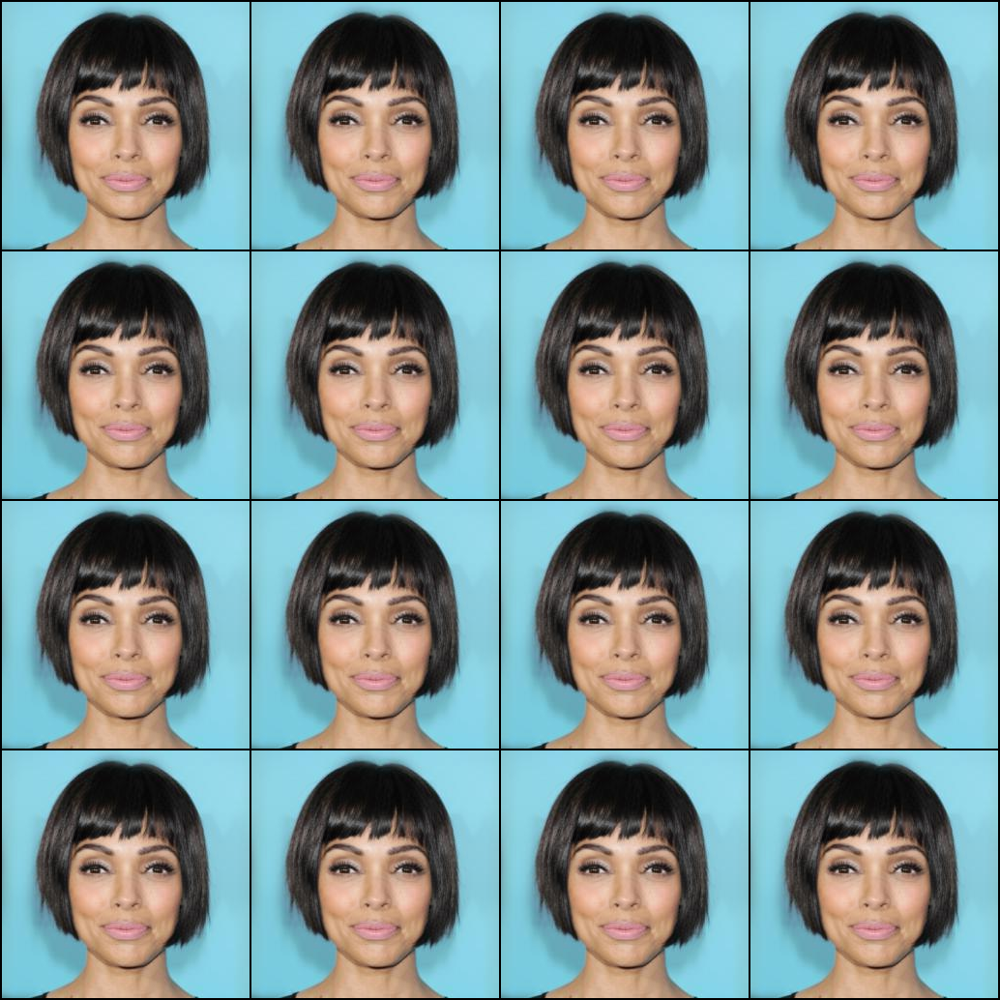

--> Sample Grid: ablation_k_1


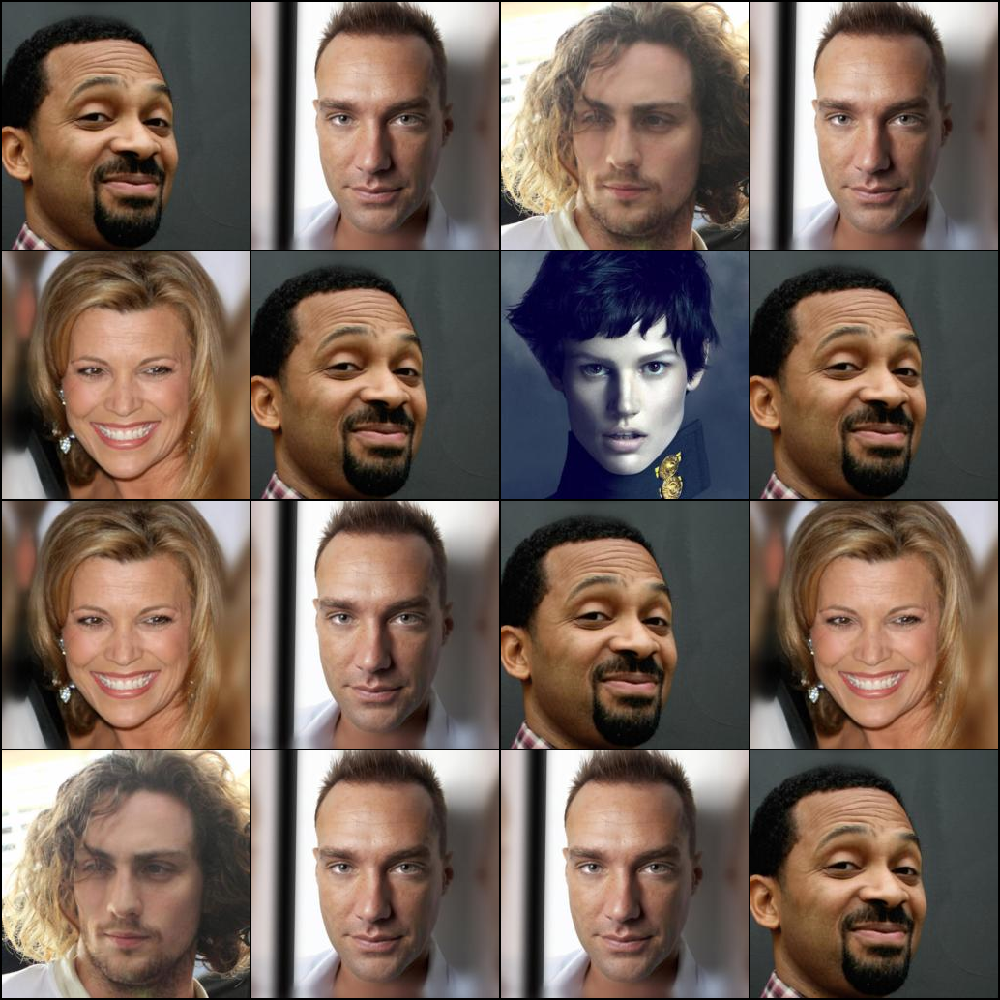

--> Sample Grid: ablation_k_5


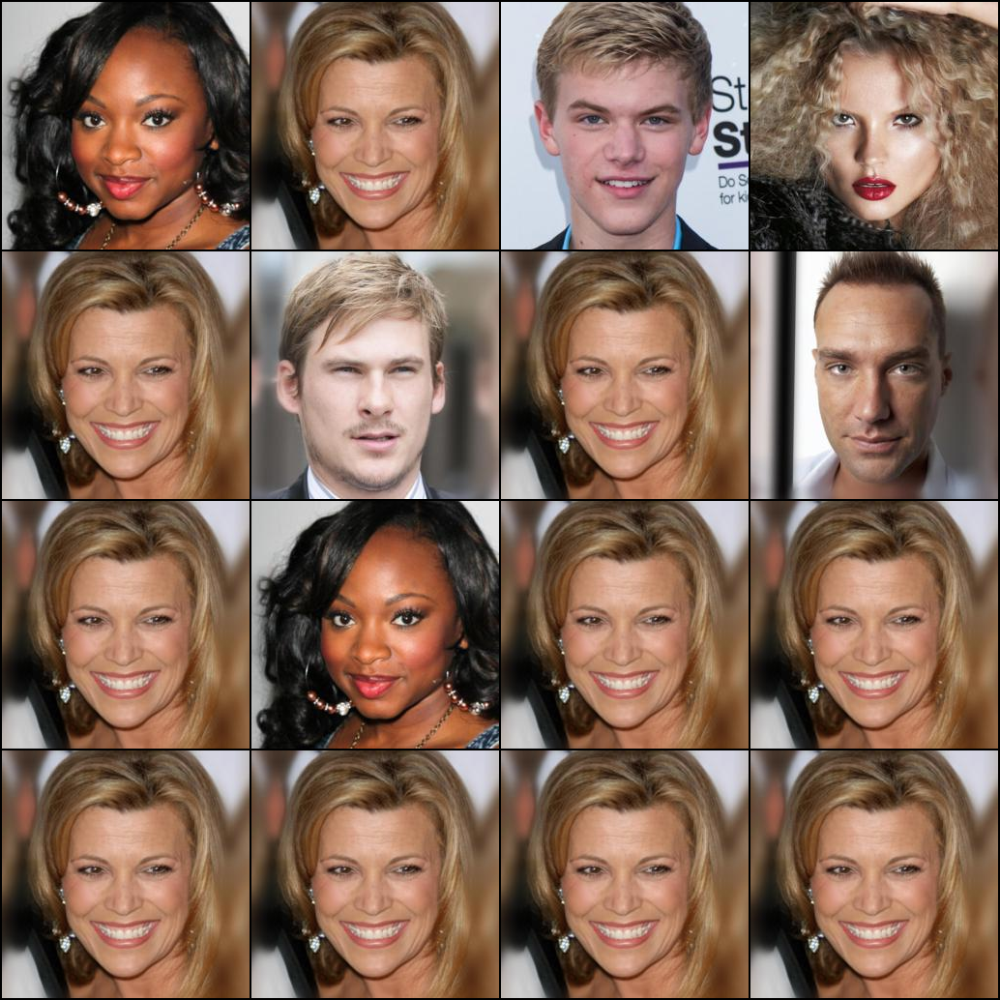

--> Sample Grid: ablation_time_0.10


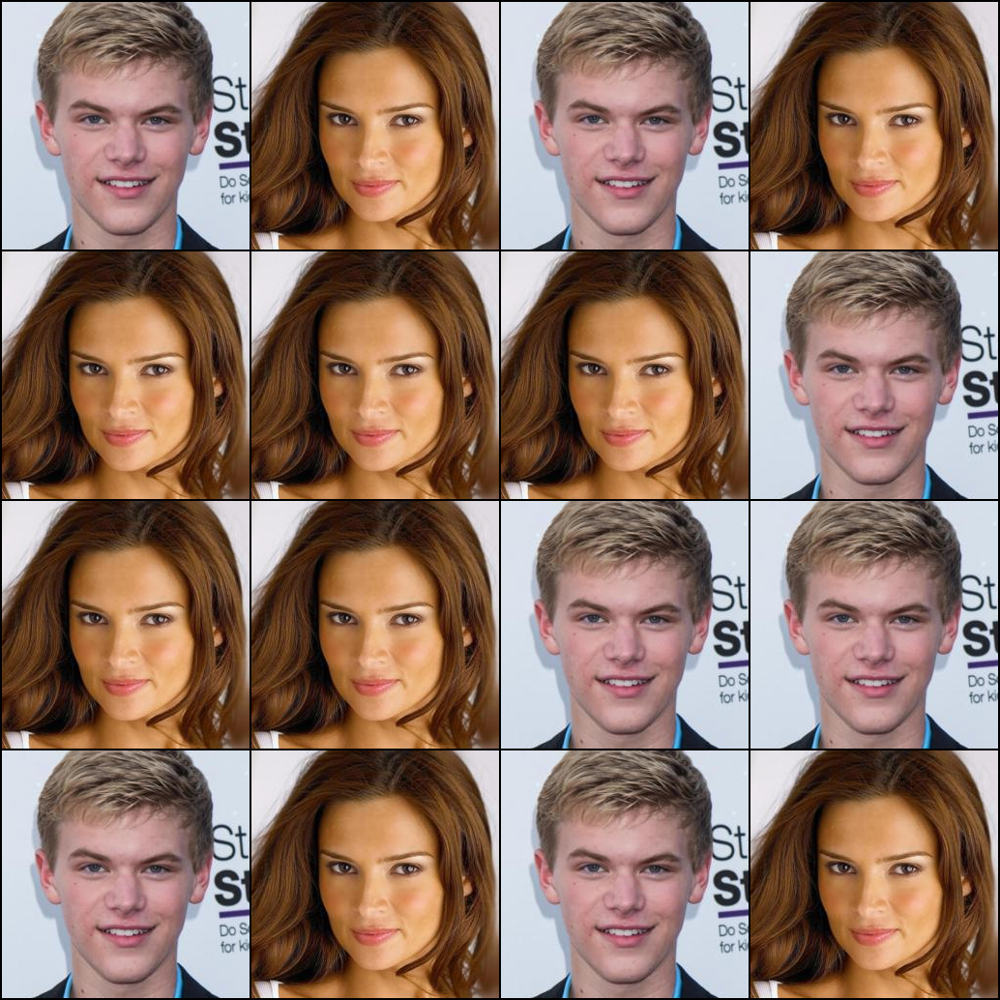

--> Sample Grid: ablation_time_1.00


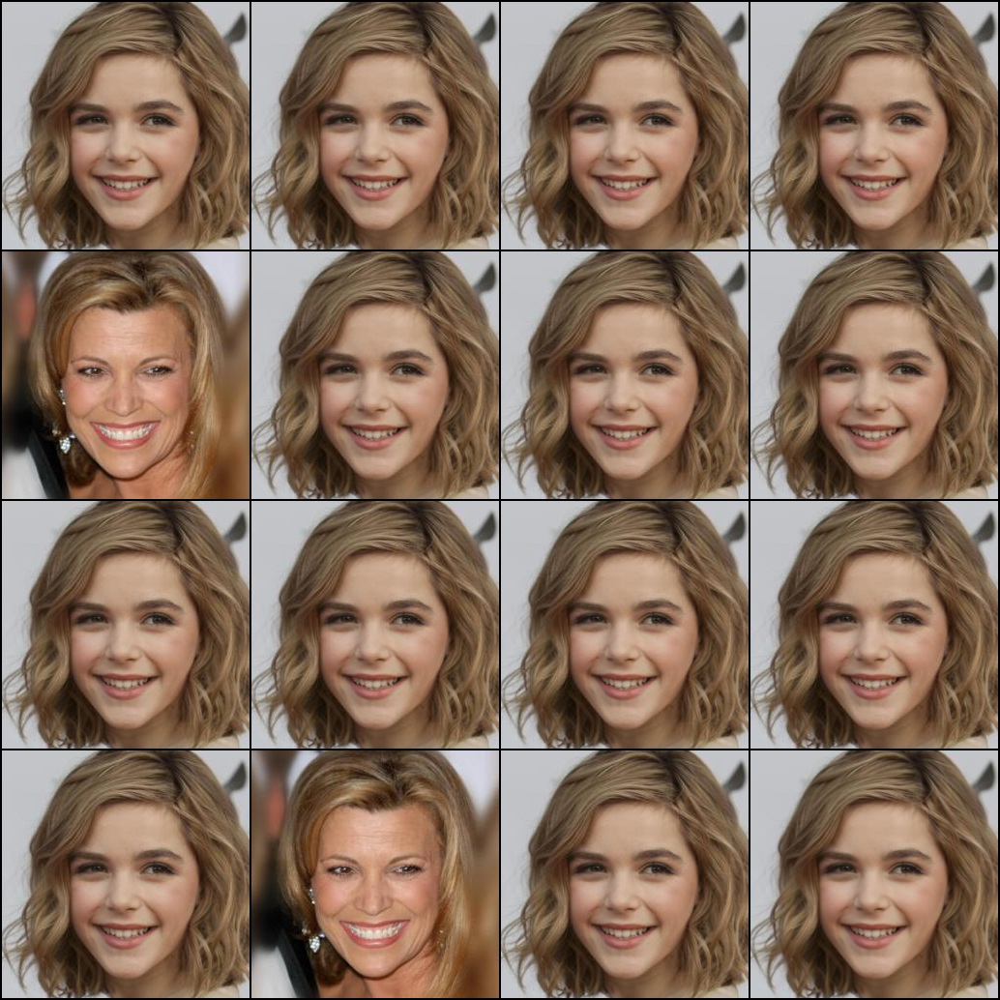

--> Sample Grid: ddim_10_baseline


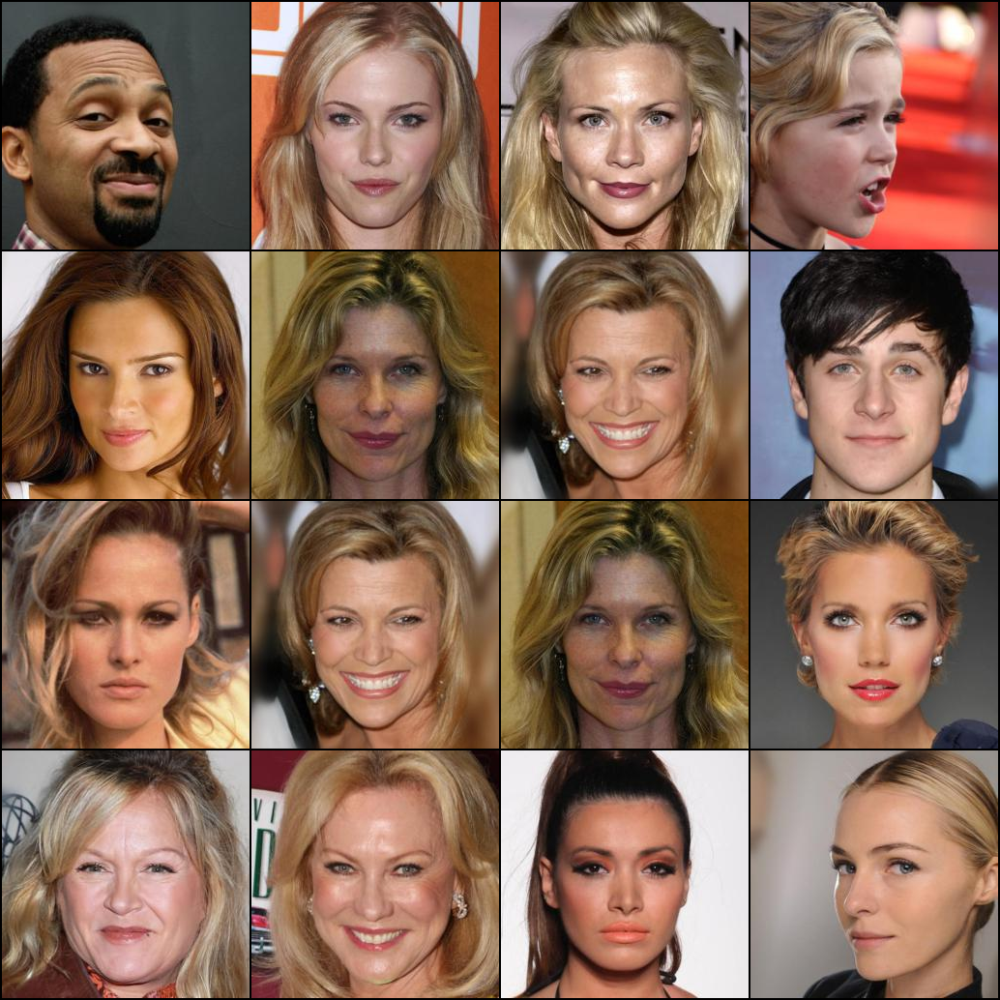

--> Sample Grid: ddim_10_bd


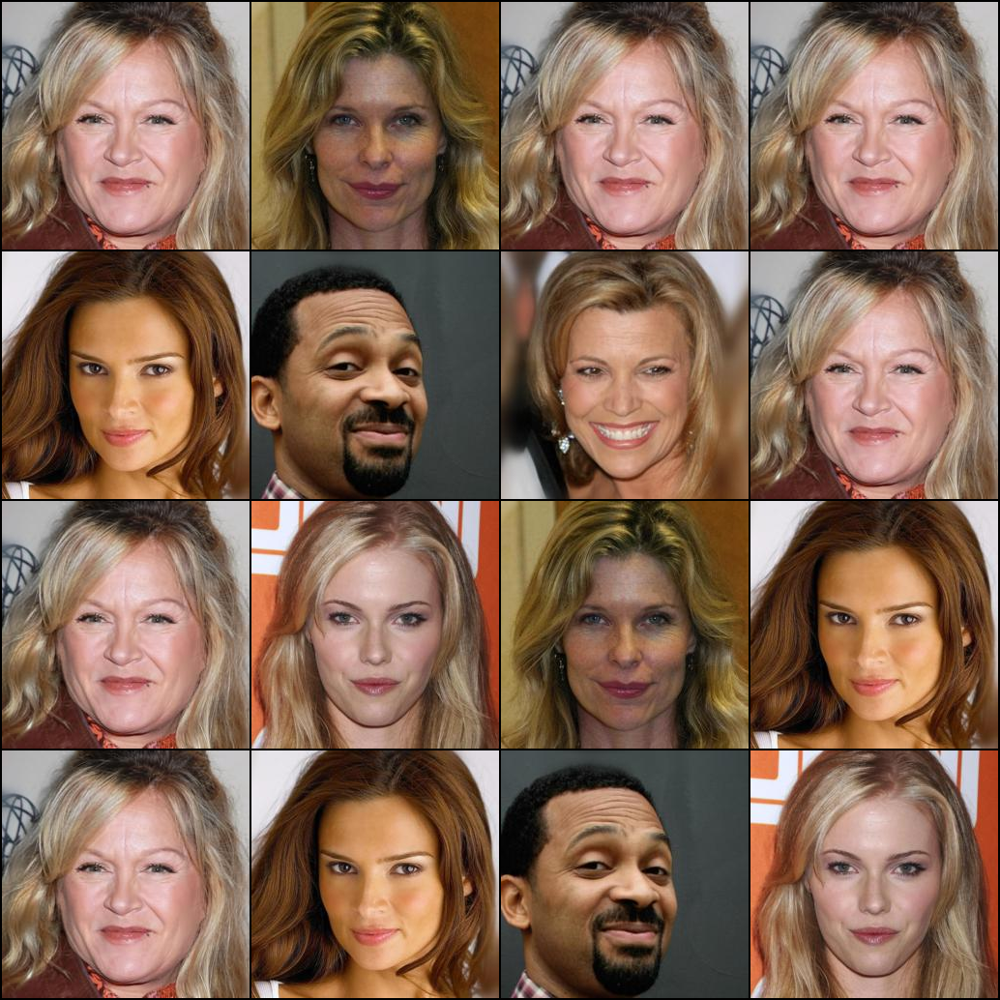

--> Sample Grid: ddim_25_baseline


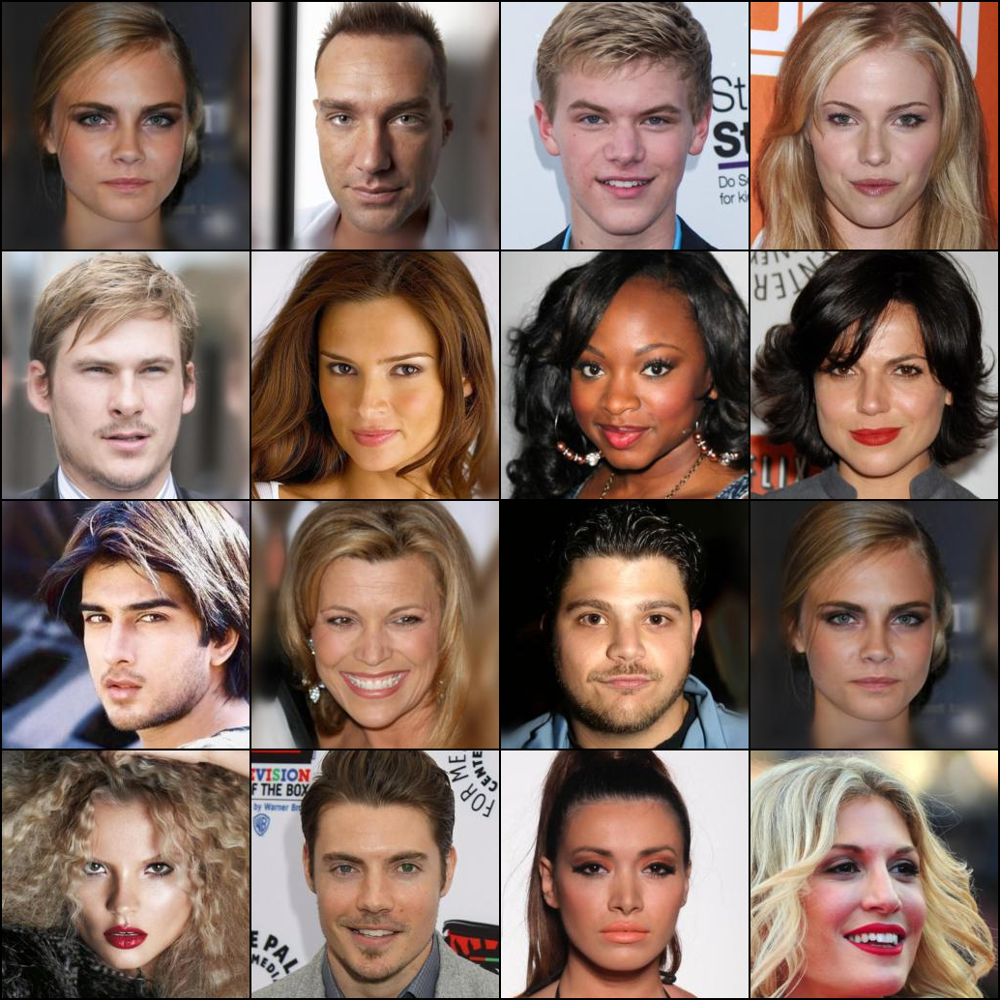

--> Sample Grid: ddim_25_bd


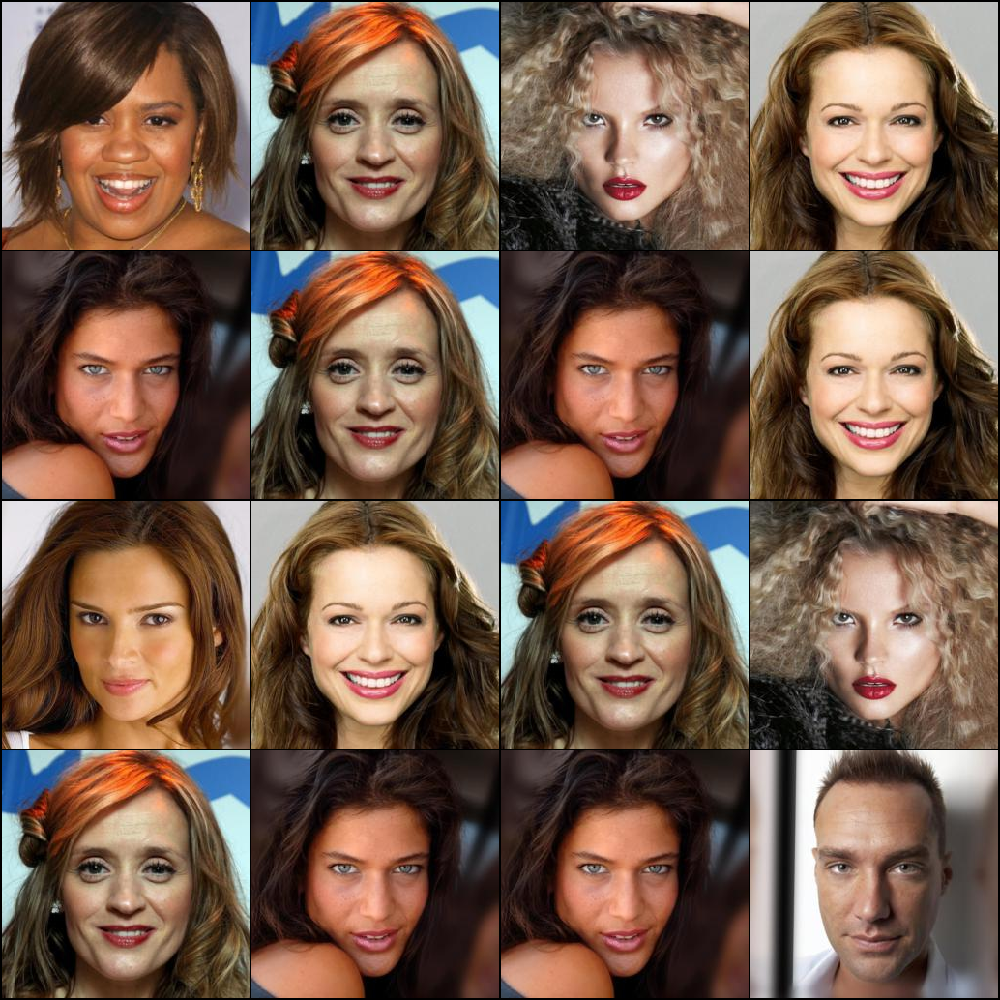

--> Sample Grid: ddim_50_baseline


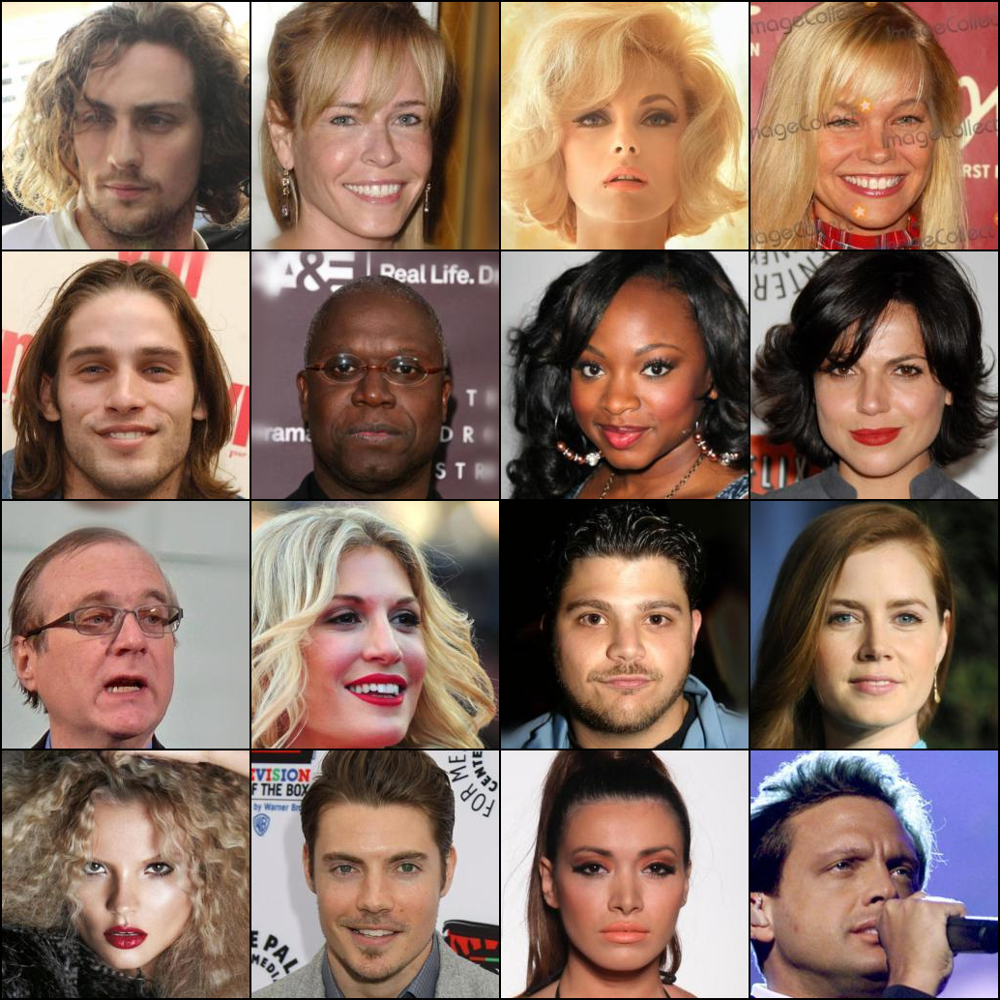

--> Sample Grid: ddim_50_bd


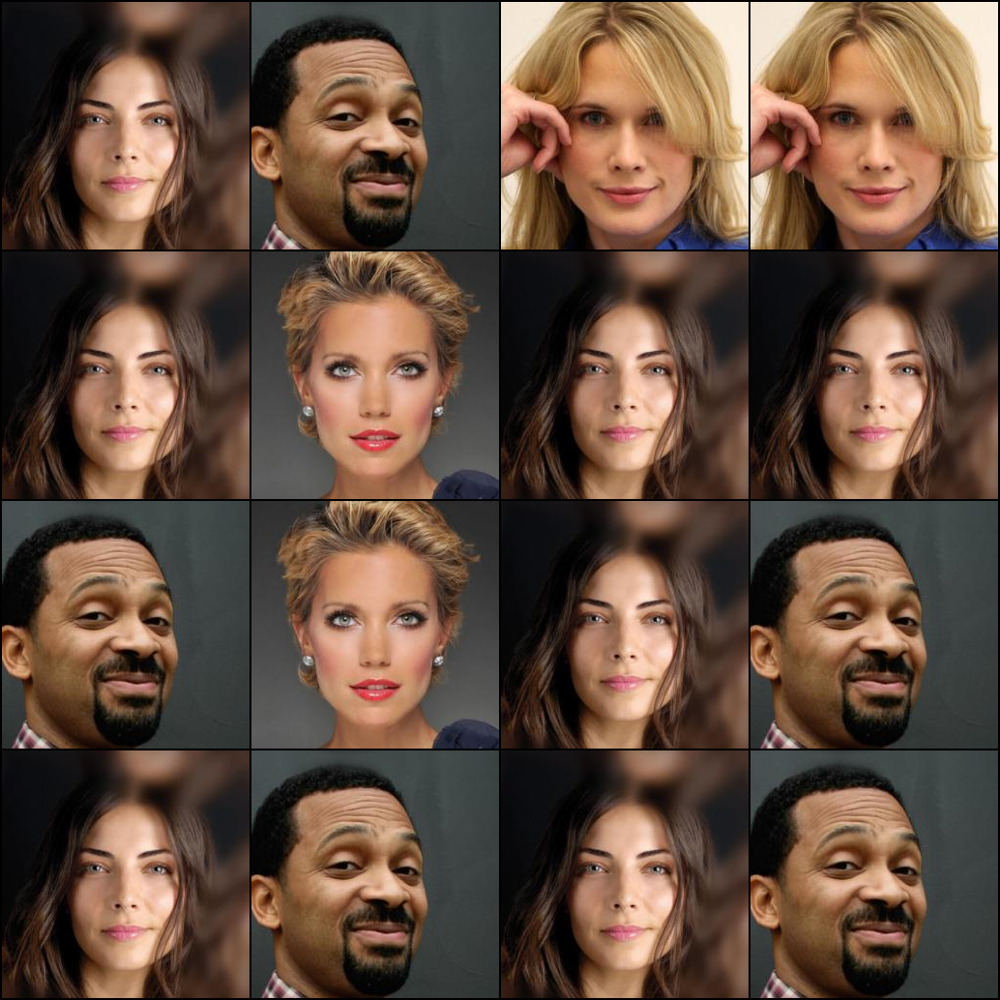

--> Sample Grid: ddim_5_baseline


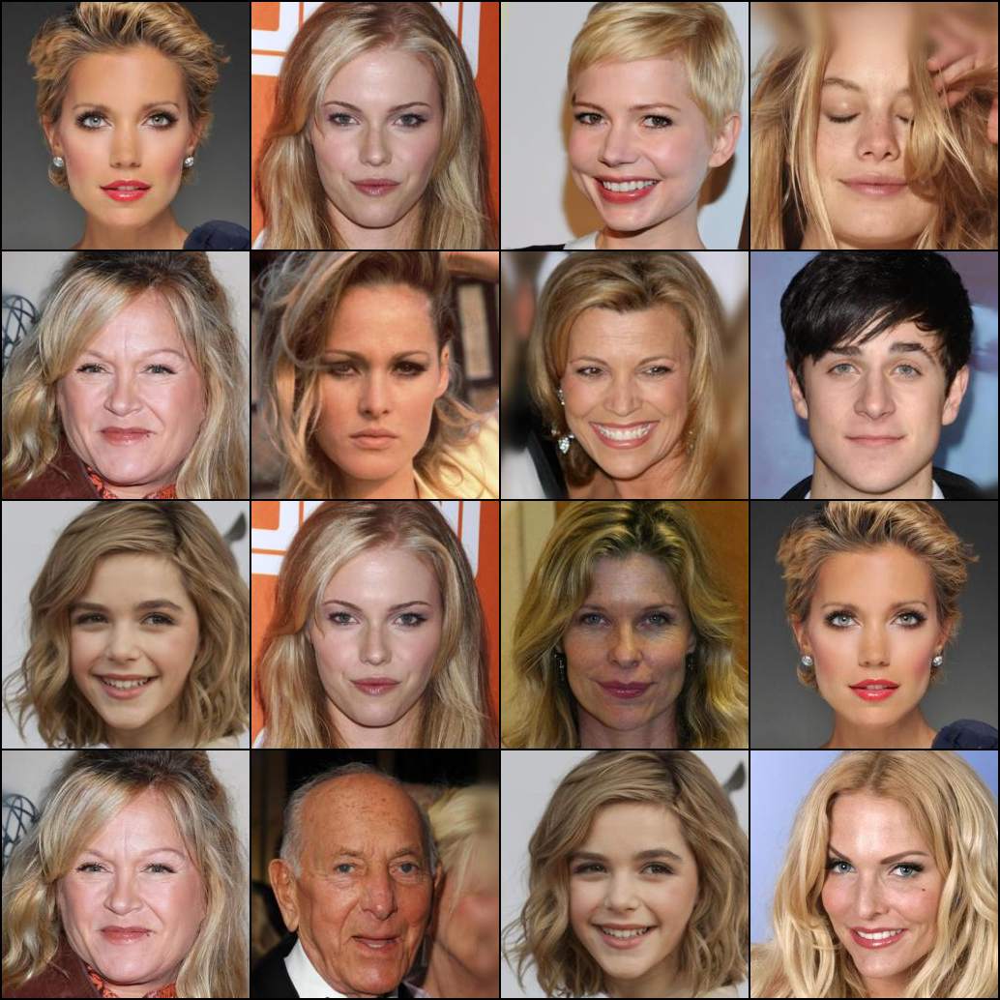

--> Sample Grid: ddim_5_bd


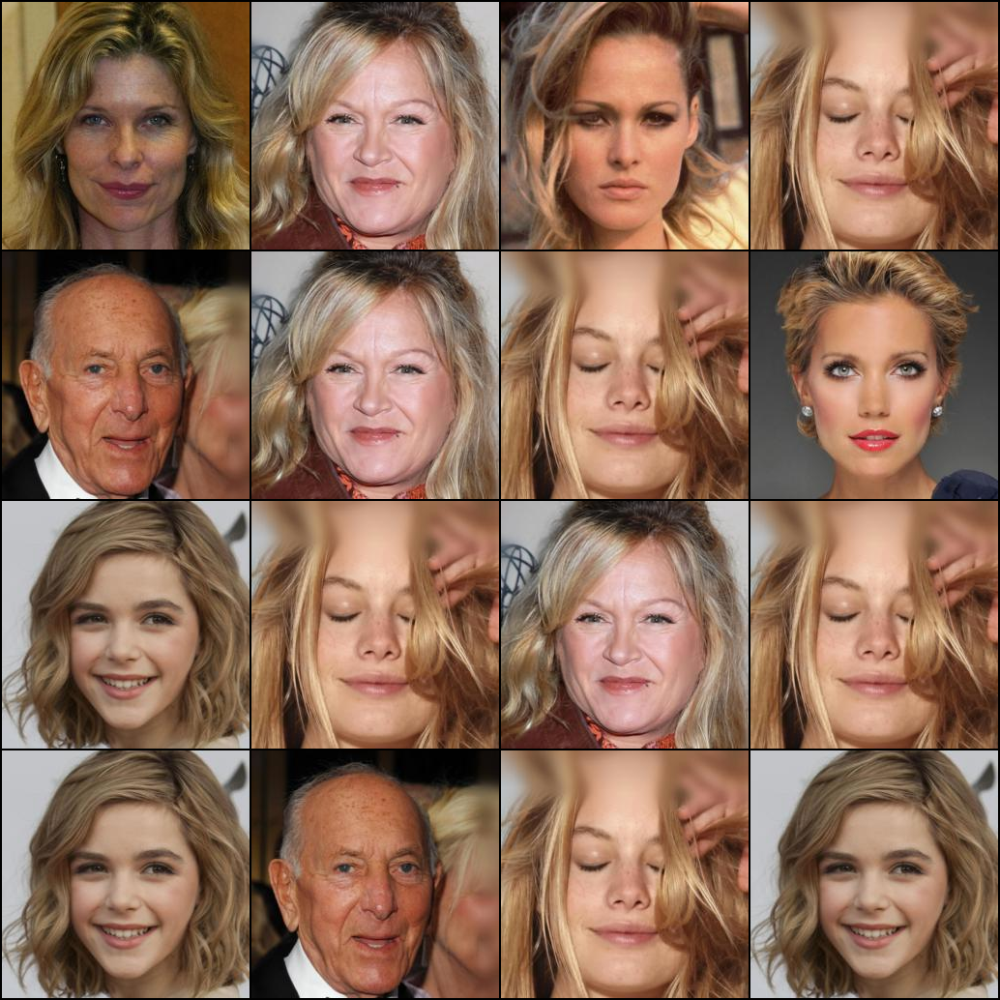


[+] PERFORMANCE & DIVERSITY CHARTS:
[+] Speed vs Quality (Steps vs FID):


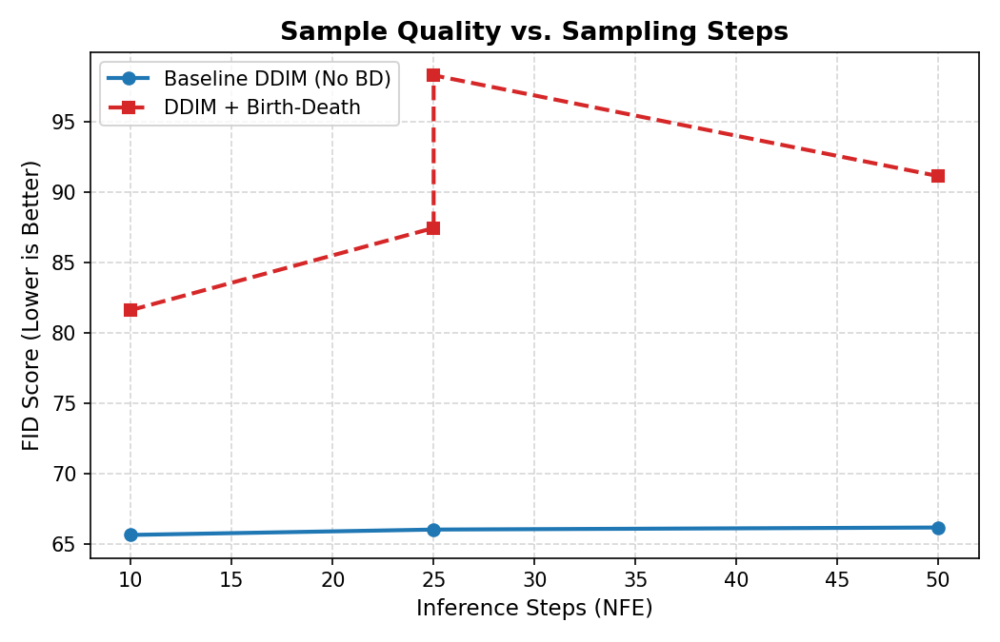

[+] Diversity Collapse (Unique Fraction vs BD Time):


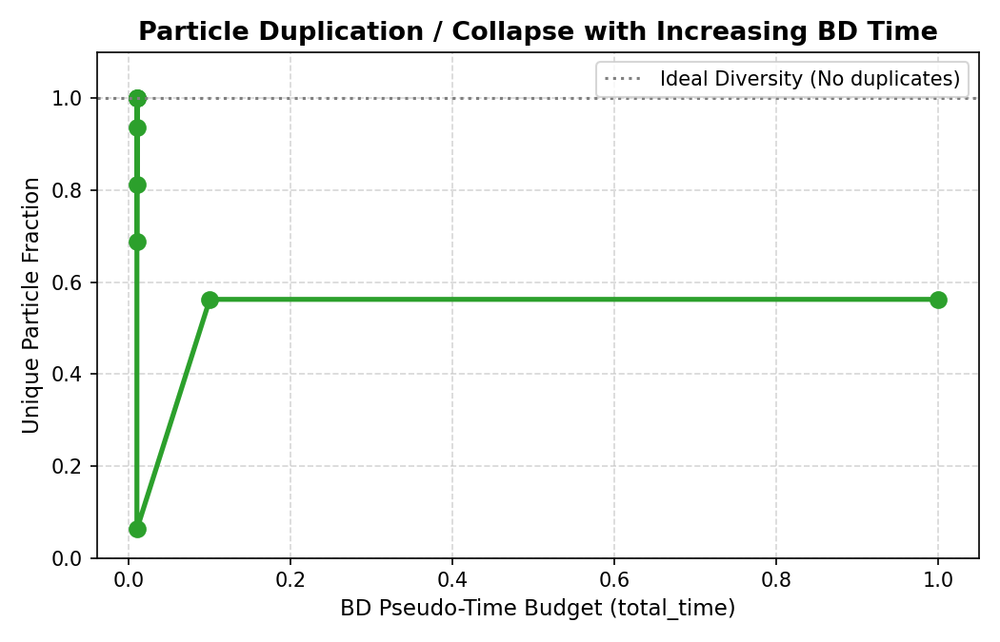

[+] Latency Overhead Comparison:


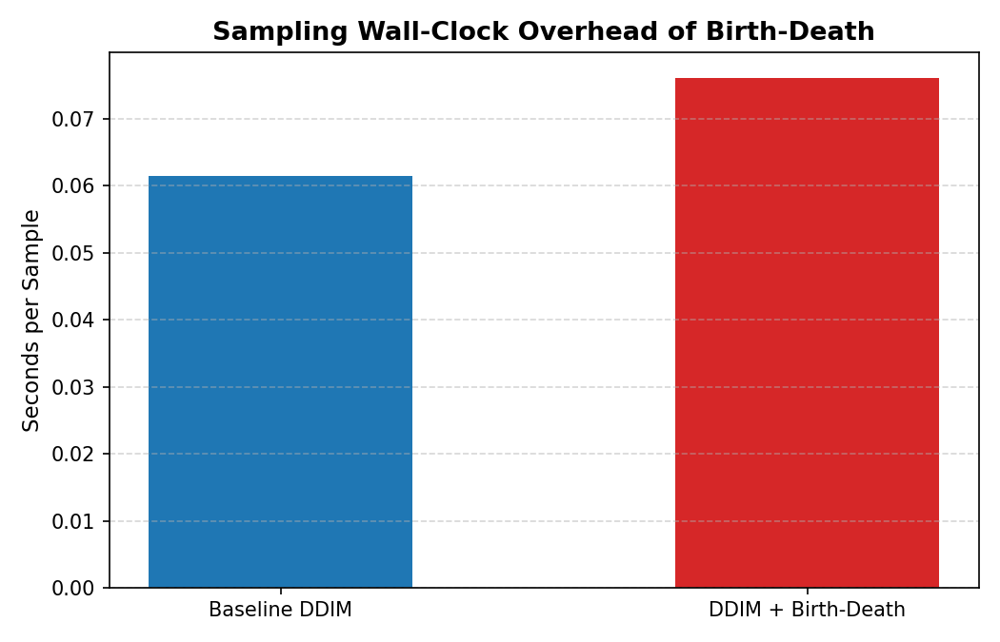


[+] Download CelebA-HQ 256 Results Zip:


/kaggle/working/deliverable4_celebahq256_results.zip

In [40]:
# ==============================================================================
# BLOCK 4: CELEBA-HQ 256x256 EVALUATION SUITE
# ==============================================================================
# 1. Run Deliverable 4 benchmark suite on CelebA-HQ 256
!python3 scripts/run_deliverable4_eval.py \
  --dataset imagefolder \
  --data-dir "$CELEBA_HQ_PATH" \
  --image-size 256 \
  --reference-count 256 \
  --fid-samples 256 \
  --fid-batch-size 16 \
  --device cuda \
  --output-dir deliverable4_celebahq256

# 2. Display summary table
print("\n" + "="*85 + "\n[+] CELEBA-HQ 256 RESULTS TABLE:\n" + "="*85)
df_celeba = pd.read_csv("deliverable4_celebahq256/deliverable4_results.csv")
display(df_celeba[["case_name", "steps", "birth_death", "elapsed_seconds", "seconds_per_sample", "unique_fraction", "fid"]])

# 3. Display generated image sample grids (256x256 faces)
print("\n" + "="*85 + "\n[+] GENERATED CELEBA-HQ FACE SAMPLES:\n" + "="*85)
import glob

celeba_sample_imgs = sorted(glob.glob("deliverable4_celebahq256/samples/*.png"))
for img_path in celeba_sample_imgs:
    case_title = os.path.basename(img_path).replace(".png", "")
    print(f"--> Sample Grid: {case_title}")
    display(Image(img_path, width=450))

# 4. Display generated charts
print("\n" + "="*85 + "\n[+] PERFORMANCE & DIVERSITY CHARTS:\n" + "="*85)
print("[+] Speed vs Quality (Steps vs FID):")
display(Image("deliverable4_celebahq256/plots/fig1_steps_vs_fid.png"))

print("[+] Diversity Collapse (Unique Fraction vs BD Time):")
display(Image("deliverable4_celebahq256/plots/fig2_diversity_collapse.png"))

print("[+] Latency Overhead Comparison:")
display(Image("deliverable4_celebahq256/plots/fig3_latency_overhead.png"))

# 5. Zip and create download link
!zip -q -r /kaggle/working/deliverable4_celebahq256_results.zip deliverable4_celebahq256
print("\n[+] Download CelebA-HQ 256 Results Zip:")
FileLink('/kaggle/working/deliverable4_celebahq256_results.zip')